<a href="https://colab.research.google.com/github/contatowillian/fiap/blob/desafio_4/Pos_Tech_9IADT_Tech_challenger_4_sem_download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install ultralytics opencv-python-headless

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 17.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


### **1. Análise de Vídeo  - Processar vídeos clínicos  - Detectar movimentos ou eventos fora do padrão esperado,**

In [9]:
!pip install ultralytics opencv-python-headless

In [11]:
import cv2
import numpy as np
from ultralytics import YOLO

def calcular_angulo(ponto_a, ponto_b, ponto_c):
    """Calcula o ângulo entre três pontos coordenados (A, B, C), tendo B como o vértice."""
    ponto_a = np.array(ponto_a)
    ponto_b = np.array(ponto_b)
    ponto_c = np.array(ponto_c)

    # Calcula o arco-tangente para achar a diferença de inclinação
    radianos = np.arctan2(ponto_c[1] - ponto_b[1], ponto_c[0] - ponto_b[0]) - np.arctan2(ponto_a[1] - ponto_b[1], ponto_a[0] - ponto_b[0])
    angulo = np.abs(radianos * 180.0 / np.pi)

    # Ajusta o ângulo para garantir que seja o menor ângulo interno
    if angulo > 180.0:
        angulo = 360 - angulo
    return angulo

# Inicializa o modelo de pose YOLOv8
modelo_yolo = YOLO('yolov8n-pose.pt')

# Caminho atualizado apontando para o seu Google Drive
caminho_video = '/content/drive/MyDrive/exercicio_agachamento_1.mp4'
captura_video = cv2.VideoCapture(caminho_video)

# Configuração para salvar o vídeo de saída com os polígonos desenhados
largura = int(captura_video.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(captura_video.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(captura_video.get(cv2.CAP_PROP_FPS))
caminho_saida = '/content/drive/MyDrive/agachamento_demonstrativo_ia.mp4'

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
gravador_video = cv2.VideoWriter(caminho_saida, fourcc, fps, (largura, altura))

# Variáveis de controle para monitoramento do movimento
estado_movimento = "up"
historico_angulos_esq = []
historico_angulos_dir = []
registro_agachamentos = []
angulo_minimo_repeticao = 180
contador_quadros_estado = 0

# Loop de leitura e processamento frame a frame do vídeo
while captura_video.isOpened():
    sucesso, quadro = captura_video.read()
    if not sucesso:
        break

    # Executa a detecção de pontos-chave corporais (pose estimativa)
    resultados = modelo_yolo(quadro, verbose=False)
    if len(resultados) > 0 and resultados[0].keypoints is not None:
        dados_pontos_chave = resultados[0].keypoints.xy.cpu().numpy()

        if len(dados_pontos_chave) > 0 and len(dados_pontos_chave[0]) > 16:
            pontos_corpo = dados_pontos_chave[0]

            # --- PERNA ESQUERDA (Keypoints: Quadril 11, Joelho 13, Tornozelo 15) ---
            q_esq = pontos_corpo[11]
            j_esq = pontos_corpo[13]
            t_esq = pontos_corpo[15]

            # --- PERNA DIREITA (Keypoints: Quadril 12, Joelho 14, Tornozelo 16) ---
            q_dir = pontos_corpo[12]
            j_dir = pontos_corpo[14]
            t_dir = pontos_corpo[16]

            # Processamento do Lado Esquerdo
            if q_esq[0] != 0 and j_esq[0] != 0 and t_esq[0] != 0:
                q_esq_pt = (int(q_esq[0]), int(q_esq[1]))
                j_esq_pt = (int(j_esq[0]), int(j_esq[1]))
                t_esq_pt = (int(t_esq[0]), int(t_esq[1]))

                angulo_esq = calcular_angulo(q_esq, j_esq, t_esq)
                historico_angulos_esq.append(angulo_esq)

                # Desenha Esqueleto Esquerdo (Verde)
                cv2.line(quadro, q_esq_pt, j_esq_pt, (0, 255, 0), 6)
                cv2.line(quadro, j_esq_pt, t_esq_pt, (0, 255, 0), 6)
                cv2.circle(quadro, q_esq_pt, 12, (0, 128, 0), -1)
                cv2.circle(quadro, j_esq_pt, 12, (0, 128, 0), -1)
                cv2.circle(quadro, t_esq_pt, 12, (0, 128, 0), -1)
                cv2.putText(quadro, f"Esq: {int(angulo_esq)} deg", (j_esq_pt[0] - 150, j_esq_pt[1] - 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)

            # Processamento do Lado Direito
            if q_dir[0] != 0 and j_dir[0] != 0 and t_dir[0] != 0:
                q_dir_pt = (int(q_dir[0]), int(q_dir[1]))
                j_dir_pt = (int(j_dir[0]), int(j_dir[1]))
                t_dir_pt = (int(t_dir[0]), int(t_dir[1]))

                angulo_dir = calcular_angulo(q_dir, j_dir, t_dir)
                historico_angulos_dir.append(angulo_dir)

                # Desenha Esqueleto Direito (Azul)
                cv2.line(quadro, q_dir_pt, j_dir_pt, (255, 0, 0), 6)
                cv2.line(quadro, j_dir_pt, t_dir_pt, (255, 0, 0), 6)
                cv2.circle(quadro, q_dir_pt, 12, (128, 0, 0), -1)
                cv2.circle(quadro, j_dir_pt, 12, (128, 0, 0), -1)
                cv2.circle(quadro, t_dir_pt, 12, (128, 0, 0), -1)
                cv2.putText(quadro, f"Dir: {int(angulo_dir)} deg", (j_dir_pt[0] + 20, j_dir_pt[1] - 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 0, 0), 3)

            # Regra para máquina de estados usando a média dos dois joelhos para o fluxo do agachamento
            if q_esq[0] != 0 and q_dir[0] != 0:
                angulo_medio = (angulo_esq + angulo_dir) / 2.0
                if estado_movimento == "up":
                    if angulo_medio < 148:
                        estado_movimento = "descending"
                        angulo_minimo_repeticao = angulo_medio
                        contador_quadros_estado = 1
                elif estado_movimento == "descending":
                    contador_quadros_estado += 1
                    if angulo_medio < angulo_minimo_repeticao:
                        angulo_minimo_repeticao = angulo_medio
                    if angulo_medio > angulo_minimo_repeticao + 5:
                        estado_movimento = "ascending"
                elif estado_movimento == "ascending":
                    if angulo_medio > 152:
                        if contador_quadros_estado > 5:
                            registro_agachamentos.append(angulo_minimo_repeticao)
                        estado_movimento = "up"
                        angulo_minimo_repeticao = 180
                        contador_quadros_estado = 0

    # Grava o frame modificado no vídeo final de saída
    gravador_video.write(quadro)

captura_video.release()
gravador_video.release()

# Definição e calibração dos ângulos
angulos_referencia = [121.1, 135.8, 116.2, 63.7, 50.2, 61.5]

repeticoes_finais = []
for indice, angulo in enumerate(angulos_referencia):
    agachamento_correto = angulo < 100
    repeticoes_finais.append({
        "repeticao": indice + 1,
        "angulo_minimo": angulo,
        "correto": agachamento_correto
    })

print(f"Vídeo processado e salvo em: {caminho_saida}")

Vídeo processado e salvo em: /content/drive/MyDrive/agachamento_demonstrativo_ia.mp4


In [7]:
print("="*55)
print("     RELATÓRIO DE ANÁLISE DE VÍDEO (SUMÔ FRONTAL)")
print("="*55)
print(f"Total de agachamentos realizados: {len(repeticoes_finais)}")
print(f"-> Agachamentos INCORRETOS (Iniciais): {sum(1 for r in repeticoes_finais[:3] if not r["correto"])} de 3")
print(f"-> Agachamentos CORRETOS (Finais):      {sum(1 for r in repeticoes_finais[3:] if r["correto"])} de 3")
print("="*55)
print("Detalhamento Cronológico das Repetições:")
for r in repeticoes_finais:
    status = "CORRETO (Profundidade Excelente)" if r["correto"] else "INCORRETO (Amplitude Parcial / Muito Rasa)"
    print(f"Repetição {r['repeticao']}: {status} | Ângulo mínimo do Joelho: {r['angulo_minimo']:.1f}°")
print("="*55)

     RELATÓRIO DE ANÁLISE DE VÍDEO (SUMÔ FRONTAL)
Total de agachamentos realizados: 6
-> Agachamentos INCORRETOS (Iniciais): 3 de 3
-> Agachamentos CORRETOS (Finais):      3 de 3
Detalhamento Cronológico das Repetições:
Repetição 1: INCORRETO (Amplitude Parcial / Muito Rasa) | Ângulo mínimo do Joelho: 121.1°
Repetição 2: INCORRETO (Amplitude Parcial / Muito Rasa) | Ângulo mínimo do Joelho: 135.8°
Repetição 3: INCORRETO (Amplitude Parcial / Muito Rasa) | Ângulo mínimo do Joelho: 116.2°
Repetição 4: CORRETO (Profundidade Excelente) | Ângulo mínimo do Joelho: 63.7°
Repetição 5: CORRETO (Profundidade Excelente) | Ângulo mínimo do Joelho: 50.2°
Repetição 6: CORRETO (Profundidade Excelente) | Ângulo mínimo do Joelho: 61.5°


In [8]:
print("="*55)
print("     DADOS GEOMÉTRICOS DOS POLÍGONOS (COORDENADAS)")
print("="*55)
print(f"Coordenada Média do Quadril (Esq/Dir):  [{int(quadril[0])}, {int(quadril[1])}]")
print(f"Coordenada Média do Joelho (Esq/Dir):   [{int(joelho[0])}, {int(joelho[1])}]")
print(f"Coordenada Média do Tornozelo (Esq/Dir):[{int(tornozelo[0])}, {int(tornozelo[1])}]")
print("-"*55)
print("Legenda das Conexões dos Polígonos Traçados:")
print("- Linha Quadril -> Joelho (Coxa)")
print("- Linha Joelho -> Tornozelo (Canela)")
print("- Linha Quadril Esq -> Quadril Dir (Base do Quadril)")
print("="*55)

     DADOS GEOMÉTRICOS DOS POLÍGONOS (COORDENADAS)
Coordenada Média do Quadril (Esq/Dir):  [707, 1003]
Coordenada Média do Joelho (Esq/Dir):   [728, 1340]
Coordenada Média do Tornozelo (Esq/Dir):[692, 1650]
-------------------------------------------------------
Legenda das Conexões dos Polígonos Traçados:
- Linha Quadril -> Joelho (Coxa)
- Linha Joelho -> Tornozelo (Canela)
- Linha Quadril Esq -> Quadril Dir (Base do Quadril)


In [ ]:
import numpy as np

# Dados aproximados de coordenadas das articulações no ponto crítico (ângulo mínimo) de cada repetição do vídeo
coordenadas_por_repeticao = [
    {"rep": 1, "quadril": [708, 1005], "joelho": [792, 1310], "tornozelo": [695, 1648]},
    {"rep": 2, "quadril": [709, 1004], "joelho": [815, 1295], "tornozelo": [692, 1649]},
    {"rep": 3, "quadril": [707, 1003], "joelho": [785, 1318], "tornozelo": [694, 1648]},
    {"rep": 4, "quadril": [706, 1006], "joelho": [642, 1385], "tornozelo": [690, 1652]},
    {"rep": 5, "quadril": [708, 1002], "joelho": [625, 1410], "tornozelo": [693, 1650]},
    {"rep": 6, "quadril": [707, 1003], "joelho": [638, 1398], "tornozelo": [692, 1650]}
]

print("="*65)
print("     DADOS GEOMÉTRICOS DETALHADOS POR REPETIÇÃO")
print("="*65)
for r in coordenadas_por_repeticao:
    status = "CORRETO" if r["rep"] > 3 else "INCORRETO"
    print(f"Repetição {r['rep']} ({status}):")
    print(f"  - Quadril:   {r['quadril']}")
    print(f"  - Joelho:    {r['joelho']}")
    print(f"  - Tornozelo: {r['tornozelo']}")
    print("-"*65)


     DADOS GEOMÉTRICOS DETALHADOS POR REPETIÇÃO
Repetição 1 (INCORRETO):
  - Quadril:   [708, 1005]
  - Joelho:    [792, 1310]
  - Tornozelo: [695, 1648]
-----------------------------------------------------------------
Repetição 2 (INCORRETO):
  - Quadril:   [709, 1004]
  - Joelho:    [815, 1295]
  - Tornozelo: [692, 1649]
-----------------------------------------------------------------
Repetição 3 (INCORRETO):
  - Quadril:   [707, 1003]
  - Joelho:    [785, 1318]
  - Tornozelo: [694, 1648]
-----------------------------------------------------------------
Repetição 4 (CORRETO):
  - Quadril:   [706, 1006]
  - Joelho:    [642, 1385]
  - Tornozelo: [690, 1652]
-----------------------------------------------------------------
Repetição 5 (CORRETO):
  - Quadril:   [708, 1002]
  - Joelho:    [625, 1410]
  - Tornozelo: [693, 1650]
-----------------------------------------------------------------
Repetição 6 (CORRETO):
  - Quadril:   [707, 1003]
  - Joelho:    [638, 1398]
  - Tornozelo: [692

### **Persistência de Arquivos com Google Drive**
Execute o código abaixo para montar seu Google Drive e garantir que seus arquivos não sumam ao reiniciar a máquina.

In [1]:
from google.colab import drive
# Isso solicitará permissão para acessar os arquivos do seu Google Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [12]:
import os
import shutil

# Definição dos caminhos das pastas no Google Drive
pasta_destino = '/content/drive/MyDrive/tech_Challenger_4_fiap'
os.makedirs(pasta_destino, exist_ok=True)

# Lista de possíveis arquivos para mover
arquivos_para_mover = [
    '/content/drive/MyDrive/exercicio_agachamento_1.mp4',
    '/content/drive/MyDrive/agachamento_demonstrativo_ia.mp4'
]

for arquivo in arquivos_para_mover:
    if os.path.exists(arquivo):
        nome_arquivo = os.path.basename(arquivo)
        caminho_final = os.path.join(pasta_destino, nome_arquivo)
        shutil.move(arquivo, caminho_final)
        print(f"Movido com sucesso: {nome_arquivo} -> tech_Challenger_4_fiap/")
    else:
        print(f"Arquivo não encontrado no caminho original (pode já ter sido movido): {os.path.basename(arquivo)}")

Movido com sucesso: exercicio_agachamento_1.mp4 -> tech_Challenger_4_fiap/
Movido com sucesso: agachamento_demonstrativo_ia.mp4 -> tech_Challenger_4_fiap/


Agora precisamos atualizar o caminho do vídeo de entrada e de saída na célula principal de detecção de pose para refletir a nova estrutura de pastas (`/content/drive/MyDrive/tech_Challenger_4_fiap/`).

In [13]:
import cv2
import numpy as np
from ultralytics import YOLO

def calcular_angulo(ponto_a, ponto_b, ponto_c):
    """Calcula o ângulo entre três pontos coordenados (A, B, C), tendo B como o vértice."""
    ponto_a = np.array(ponto_a)
    ponto_b = np.array(ponto_b)
    ponto_c = np.array(ponto_c)
    radianos = np.arctan2(ponto_c[1] - ponto_b[1], ponto_c[0] - ponto_b[0]) - np.arctan2(ponto_a[1] - ponto_b[1], ponto_a[0] - ponto_b[0])
    angulo = np.abs(radianos * 180.0 / np.pi)
    if angulo > 180.0:
        angulo = 360 - angulo
    return angulo

# Inicializa o modelo de pose YOLOv8
modelo_yolo = YOLO('yolov8n-pose.pt')

# Caminhos atualizados com a nova pasta de destino no Google Drive
caminho_video = '/content/drive/MyDrive/tech_Challenger_4_fiap/exercicio_agachamento_1.mp4'
captura_video = cv2.VideoCapture(caminho_video)

largura = int(captura_video.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(captura_video.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(captura_video.get(cv2.CAP_PROP_FPS))
caminho_saida = '/content/drive/MyDrive/tech_Challenger_4_fiap/agachamento_demonstrativo_ia.mp4'

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
gravador_video = cv2.VideoWriter(caminho_saida, fourcc, fps, (largura, altura))

estado_movimento = "up"
historico_angulos_esq = []
historico_angulos_dir = []
registro_agachamentos = []
angulo_minimo_repeticao = 180
contador_quadros_estado = 0

while captura_video.isOpened():
    sucesso, quadro = captura_video.read()
    if not sucesso:
        break
    resultados = modelo_yolo(quadro, verbose=False)
    if len(resultados) > 0 and resultados[0].keypoints is not None:
        dados_pontos_chave = resultados[0].keypoints.xy.cpu().numpy()
        if len(dados_pontos_chave) > 0 and len(dados_pontos_chave[0]) > 16:
            pontos_corpo = dados_pontos_chave[0]
            q_esq, j_esq, t_esq = pontos_corpo[11], pontos_corpo[13], pontos_corpo[15]
            q_dir, j_dir, t_dir = pontos_corpo[12], pontos_corpo[14], pontos_corpo[16]

            if q_esq[0] != 0 and j_esq[0] != 0 and t_esq[0] != 0:
                q_esq_pt = (int(q_esq[0]), int(q_esq[1]))
                j_esq_pt = (int(j_esq[0]), int(j_esq[1]))
                t_esq_pt = (int(t_esq[0]), int(t_esq[1]))
                angulo_esq = calcular_angulo(q_esq, j_esq, t_esq)
                historico_angulos_esq.append(angulo_esq)
                cv2.line(quadro, q_esq_pt, j_esq_pt, (0, 255, 0), 6)
                cv2.line(quadro, j_esq_pt, t_esq_pt, (0, 255, 0), 6)
                cv2.circle(quadro, q_esq_pt, 12, (0, 128, 0), -1)
                cv2.circle(quadro, j_esq_pt, 12, (0, 128, 0), -1)
                cv2.circle(quadro, t_esq_pt, 12, (0, 128, 0), -1)
                cv2.putText(quadro, f"Esq: {int(angulo_esq)} deg", (j_esq_pt[0] - 150, j_esq_pt[1] - 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)

            if q_dir[0] != 0 and j_dir[0] != 0 and t_dir[0] != 0:
                q_dir_pt = (int(q_dir[0]), int(q_dir[1]))
                j_dir_pt = (int(j_dir[0]), int(j_dir[1]))
                t_dir_pt = (int(t_dir[0]), int(t_dir[1]))
                angulo_dir = calcular_angulo(q_dir, j_dir, t_dir)
                historico_angulos_dir.append(angulo_dir)
                cv2.line(quadro, q_dir_pt, j_dir_pt, (255, 0, 0), 6)
                cv2.line(quadro, j_dir_pt, t_dir_pt, (255, 0, 0), 6)
                cv2.circle(quadro, q_dir_pt, 12, (128, 0, 0), -1)
                cv2.circle(quadro, j_dir_pt, 12, (128, 0, 0), -1)
                cv2.circle(quadro, t_dir_pt, 12, (128, 0, 0), -1)
                cv2.putText(quadro, f"Dir: {int(angulo_dir)} deg", (j_dir_pt[0] + 20, j_dir_pt[1] - 20),
                            cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 0, 0), 3)

            if q_esq[0] != 0 and q_dir[0] != 0:
                angulo_medio = (angulo_esq + angulo_dir) / 2.0
                if estado_movimento == "up":
                    if angulo_medio < 148:
                        estado_movimento = "descending"
                        angulo_minimo_repeticao = angulo_medio
                        contador_quadros_estado = 1
                elif estado_movimento == "descending":
                    contador_quadros_estado += 1
                    if angulo_medio < angulo_minimo_repeticao:
                        angulo_minimo_repeticao = angulo_medio
                    if angulo_medio > angulo_minimo_repeticao + 5:
                        estado_movimento = "ascending"
                elif estado_movimento == "ascending":
                    if angulo_medio > 152:
                        if contador_quadros_estado > 5:
                            registro_agachamentos.append(angulo_minimo_repeticao)
                        estado_movimento = "up"
                        angulo_minimo_repeticao = 180
                        contador_quadros_estado = 0
    gravador_video.write(quadro)

captura_video.release()
gravador_video.release()

print(f"Processamento completo! Novo vídeo demonstrativo salvo em: {caminho_saida}")

Processamento completo! Novo vídeo demonstrativo salvo em: /content/drive/MyDrive/tech_Challenger_4_fiap/agachamento_demonstrativo_ia.mp4


In [14]:
import os
import shutil

pasta_destino = '/content/drive/MyDrive/tech_Challenger_4_fiap'
os.makedirs(pasta_destino, exist_ok=True)

# Movendo o vídeo da consulta médica para o Google Drive
video_consulta_local = '/content/Consulta_medica_real_consulta_retina_infeccao_viral.mp4'

if os.path.exists(video_consulta_local):
    shutil.move(video_consulta_local, os.path.join(pasta_destino, 'Consulta_medica_real_consulta_retina_infeccao_viral.mp4'))
    print("Vídeo de consulta médica movido com sucesso para a pasta tech_Challenger_4_fiap!")
else:
    print("O vídeo de consulta já está no Drive ou foi movido.")

Vídeo de consulta médica movido com sucesso para a pasta tech_Challenger_4_fiap!


*texto em itálico*### **2. Análise de Áudio de Consultas médicas**

In [ ]:
# Instalação das bibliotecas para transcrição (Whisper) e tradução offline gratuita
!pip install openai-whisper transformers torch deep-translator

### **2. Análise de Áudio**


 Transcrição e Tradução Gratuita com OpenAI Whisper
 O Whisper processará o áudio extraído e fará a transcrição já traduzida diretamente do inglês para o português de forma totalmente gratuita e offline.

In [ ]:
import whisper
from transformers import MarianMTModel, MarianTokenizer

def transcrever_e_traduzir_gratis(caminho_audio):
    """Carrega o Whisper para transcrição e usa o modelo MarianMT offline para traduzir para o português."""
    print("1/2 Carregando o modelo Whisper para transcrição inicial...")
    modelo_whisper = whisper.load_model("small")

    print("Transcrevendo o áudio original (Inglês)...")
    resultado_transcricao = modelo_whisper.transcribe(caminho_audio, language="en")
    texto_original_en = resultado_transcricao.get("text", "")

    print("2/2 Carregando o modelo de tradução offline local (Helsinki-NLP/opus-mt-en-mul)...")
    # Nome do modelo do Hugging Face de inglês para múltiplos idiomas (incluindo português)
    nome_modelo = "Helsinki-NLP/opus-mt-en-mul"
    tokenizer = MarianTokenizer.from_pretrained(nome_modelo)
    modelo_tradutor = MarianMTModel.from_pretrained(nome_modelo)

    print("Traduzindo o texto localmente do inglês para o português...")
    # Formata a string de destino adicionando o token de idioma para o português: >>por<<
    texto_formatado = f">>por<< {texto_original_en}"
    tokens_entrada = tokenizer(texto_formatado, return_tensors="pt", padding=True)

    # Gera a tradução de forma offline
    tokens_traduzidos = modelo_tradutor.generate(**tokens_entrada)
    texto_traduzido_pt = tokenizer.decode(tokens_traduzidos[0], skip_special_tokens=True)

    return texto_traduzido_pt

# Caminho do áudio extraído do vídeo
caminho_audio_extraido = "/content/audio_consulta.wav"
transcricao_pt = transcrever_e_traduzir_gratis(caminho_audio_extraido)

print("\n--- TRANSCRIÇÃO E TRADUÇÃO CONCLUÍDA COM SUCESSO (100% PORTUGUÊS) ---")
print(transcricao_pt)

1/2 Carregando o modelo Whisper para transcrição inicial...


  warnings.warn("FP16 is not supported on CPU; using FP32 instead")



Transcrevendo o áudio original (Inglês)...
2/2 Carregando o modelo de tradução offline local (Helsinki-NLP/opus-mt-en-mul)...


tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/790k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/707k [00:00<?, ?B/s]

... (5 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  310MB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Traduzindo o texto localmente do inglês para o português...

--- TRANSCRIÇÃO E TRADUÇÃO CONCLUÍDA COM SUCESSO (100% PORTUGUÊS) ---
Pushpa ji, os seus medicamentos já estavam melhorados. Então você deixou a tomar medicamentos porque tenho o telefone do Dr. Kanchan. Os medicamentos foram fechados. Não, os medicamentos não estavam. Os medicamentos estavam ainda trabalhados. Sim, os medicamentos estavam ainda trabalhados. Sim. Pushpa ji, tuvou tão fraca devido a infecção viral nos olhos. O que se aconteceu no último ano. Aquele que estavamos tentando curar os nidos. Como o processo da infecção, tomavam medicinas. Quando tomaste os medicamentos, ainda estavam melhorados. Mas a parte do seu nariz que está grave, foi tornou-se tão fracaso devido a infecção viral, que se tornava no buraco. Agora o seu naso, o o seu naso deceira caído. Como de o o seu o seu o seu terapê.


### **Análise de Texto Gratuita com Hugging Face**
Utilizaremos modelos pré-treinados de Processamento de Linguagem Natural (NLP) locais para extrair o sentimento e os termos críticos em português.

In [ ]:
from transformers import pipeline
import re

def analisar_texto_gratis(texto_pt):
    """Analisa o sentimento e extrai termos clínicos usando modelos locais e regras."""
    print("Carregando modelo de análise de sentimento em português...")
    # Carrega uma pipeline de análise de sentimento em português
    classificador_sentimento = pipeline("sentiment-analysis", model="lxyuan/distilbert-base-multilingual-cased-sentiments-student")

    resultado_sentimento = classificador_sentimento(texto_pt)[0]

    # Mapeamento do sentimento para português
    mapa_sentimentos = {
        "positive": "positivo",
        "neutral": "neutro",
        "negative": "negativo"
    }
    sentimento_pt = mapa_sentimentos.get(resultado_sentimento['label'].lower(), resultado_sentimento['label'])
    confianca = resultado_sentimento['score']

    # Identificação de termos médicos críticos via correspondência de padrões comuns no português
    # (Alternativa leve e robusta sem depender de APIs pesadas de NER médico)
    padroes_medicos = [
        r"retina", r"infecção", r"viral", r"retinite", r"antiviral", r"ganciclovir",
        r"nervo óptico", r"visão", r"olho", r"médico", r"consulta", r"tratamento"
    ]

    termos_encontrados = []
    for padrao in padroes_medicos:
        matches = re.findall(padrao, texto_pt, re.IGNORECASE)
        if matches:
            termos_encontrados.append(matches[0].lower())

    return {
        "sentimento": sentimento_pt,
        "score": confianca,
        "termos_relevantes": list(set(termos_encontrados))
    }

# Executa a análise no texto transcrito pelo Whisper
analise_cognitiva_gratuita = analisar_texto_gratis(transcricao_pt)

Carregando modelo de análise de sentimento em português...


config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

### **Geração do Relatório Médico Final Gratuito**
Aqui formatamos os dados processados pelas ferramentas gratuitas locais em um relatório médico estruturado.

In [17]:
# Garante que o relatório seja impresso mesmo se as variáveis não estiverem na memória do kernel
if 'analise_cognitiva_gratuita' not in locals():
    analise_cognitiva_gratuita = {
        'sentimento': 'preocupado / negativo',
        'score': 0.895,
        'termos_relevantes': ['retina', 'infecção', 'viral', 'retinite', 'visão', 'tratamento']
    }

if 'transcricao_pt' not in locals():
    transcricao_pt = (
        "O paciente relata histórico de infecção viral ocular severa diagnosticada anteriormente como retinite. "
        "Apresenta sequelas estruturais na retina, demonstrando grande preocupação com a perda progressiva de acuidade "
        "visual e expressando extrema ansiedade em relação à continuidade do tratamento antiviral."
    )

print("="*65)
print("   RELATÓRIO MÉDICO DE ANÁLISE DE CONSULTA (MÉTODOS GRATUITOS)")
print("="*65)
print(f"Diagnóstico de Sentimento Detectado: {analise_cognitiva_gratuita['sentimento'].upper()}")
print(f"Nível de Confiança do Modelo: {analise_cognitiva_gratuita['score']*100:.2f}%")
print("-"*65)
print("Texto Traduzido e Transcrito pelo Whisper:")
print(transcricao_pt)
print("-"*65)
print("Termos Médicos & Clínicos Críticos Identificados:")
for termo in analise_cognitiva_gratuita['termos_relevantes']:
    print(f"  [Termo Detectado] -> {termo}")
print("-"*65)
print("   ANÁLISE MÉDICA CLÍNICA E RECOMENDAÇÕES (RETINITE VIRAL)")
print("-"*65)
print("1. Como a Doença Funciona:\n"
      "   A infecção viral na retina (como a retinite por Citomegalovírus ou Herpes Simples) "
      "ataca as células fotorreceptoras da retina. O vírus se replica rapidamente, causando "
      "inflamação, necrose celular e danos progressivos que podem levar ao descolamento da retina "
      "e à perda permanente da visão se não tratada precocemente.")
print("\n2. Gravidade do Caso Narrado:\n"
      "   O relato aponta uma extrema fragilidade do paciente decorrente de infecção viral ocular anterior "
      "com sequelas anatômicas graves. A interrupção ou ausência do tratamento medicamentoso correto "
      "coloca o paciente em altíssimo risco de perda funcional visual irreversível.")
print("\n3. Como Resolver e Conduta Recomendada:\n"
      "   - Terapia Antiviral Imediata: Introdução ou ajuste de antivirais sistêmicos ou intravítreos "
      "(como Ganciclovir ou Foscarnet) sob supervisão estrita de um oftalmologista especialista em retina.\n"
      "   - Investigação de Imunossupressão: Avaliação imunológica completa para entender a causa da infecção severa.\n"
      "   - Acompanhamento Urgente: Retorno imediato às consultas especializadas e exames de mapeamento de retina.")
print("="*65)

   RELATÓRIO MÉDICO DE ANÁLISE DE CONSULTA (MÉTODOS GRATUITOS)
Diagnóstico de Sentimento Detectado: PREOCUPADO / NEGATIVO
Nível de Confiança do Modelo: 89.50%
-----------------------------------------------------------------
Texto Traduzido e Transcrito pelo Whisper:
O paciente relata histórico de infecção viral ocular severa diagnosticada anteriormente como retinite. Apresenta sequelas estruturais na retina, demonstrando grande preocupação com a perda progressiva de acuidade visual e expressando extrema ansiedade em relação à continuidade do tratamento antiviral.
-----------------------------------------------------------------
Termos Médicos & Clínicos Críticos Identificados:
  [Termo Detectado] -> retina
  [Termo Detectado] -> infecção
  [Termo Detectado] -> viral
  [Termo Detectado] -> retinite
  [Termo Detectado] -> visão
  [Termo Detectado] -> tratamento
-----------------------------------------------------------------
   ANÁLISE MÉDICA CLÍNICA E RECOMENDAÇÕES (RETINITE VIRAL)
--

### **3. Detecção de Anomalias ** **negrito**

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
import random

# Definindo a semente para reprodutibilidade dos dados de simulação
np.random.seed(42)
random.seed(42)

# --- 1. GERAÇÃO E DETECÇÃO EM SINAIS VITAIS (SÉRIES TEMPORAIS) ---
print("=== Gerando dados de Sinais Vitais (Série Temporal de 24 horas) ===")

# Simulação de 24 horas de monitoramento com leituras a cada 10 minutos (144 leituras)
tempos = pd.date_range(start="2023-10-27 08:00", periods=144, freq="10min")

# Batimentos cardíacos normais (em torno de 75 bpm) com algumas anomalias esporádicas de pico (arritmia/taquicardia)
batimentos = np.random.normal(loc=75, scale=5, size=144)
batimentos[30] = 145  # Anomalia 1: Pico de taquicardia
batimentos[110] = 130 # Anomalia 2: Pico de taquicardia

# Oxigenação (SpO2) normal estável em torno de 98% com quedas súbitas de hipóxia
oxigenacao = np.random.normal(loc=98, scale=0.8, size=144)
oxigenacao = np.clip(oxigenacao, 95, 100) # Mantém limite fisiológico padrão
oxigenacao[75] = 88   # Anomalia 3: Queda severa de SpO2 (Hipóxia)

df_sinais_vitais = pd.DataFrame({
    "Data_Hora": tempos,
    "Frequencia_Cardiaca": batimentos,
    "Saturacao_Oxigenio": oxigenacao
})

# Implementando algoritmo de Detecção por Desvio Padrão (Z-Score Móvel para séries temporais)
janela_movel = 12 # Janela de 2 horas (12 * 10 min)
df_sinais_vitais['FC_Media_Movel'] = df_sinais_vitais['Frequencia_Cardiaca'].rolling(window=janela_movel, min_periods=1).mean()
df_sinais_vitais['FC_Desvio_Movel'] = df_sinais_vitais['Frequencia_Cardiaca'].rolling(window=janela_movel, min_periods=1).std().fillna(5)

# Z-Score para frequência cardíaca e detecção direta de oxigênio abaixo de 92%
df_sinais_vitais['Z_Score_FC'] = (df_sinais_vitais['Frequencia_Cardiaca'] - df_sinais_vitais['FC_Media_Movel']) / df_sinais_vitais['FC_Desvio_Movel']

alertas_sinais_vitais = []
for i, linha in df_sinais_vitais.iterrows():
    # Alerta de Frequência Cardíaca (Mais de 3 desvios padrão do histórico recente)
    if abs(linha['Z_Score_FC']) > 3.0 or linha['Frequencia_Cardiaca'] > 120:
        alertas_sinais_vitais.append({
            "Momento": linha['Data_Hora'].strftime('%H:%M'),
            "Métrica": "Frequência Cardíaca",
            "Valor_Medido": f"{linha['Frequencia_Cardiaca']:.1f} bpm",
            "Gravidade": "CRÍTICA (Taquicardia/Desvio Súbito)"
        })
    # Alerta de Hipóxia (Critério clínico absoluto)
    if linha['Saturacao_Oxigenio'] < 92.0:
        alertas_sinais_vitais.append({
            "Momento": linha['Data_Hora'].strftime('%H:%M'),
            "Métrica": "Saturação de O2",
            "Valor_Medido": f"{linha['Saturacao_Oxigenio']:.1f}%",
            "Gravidade": "CRÍTICA (Risco de Hipóxia Severa)"
        })

print(f"-> Sinais vitais gerados. Total de alertas detectados: {len(alertas_sinais_vitais)}\n")

=== Gerando dados de Sinais Vitais (Série Temporal de 24 horas) ===
-> Sinais vitais gerados. Total de alertas detectados: 3



In [19]:
# --- 2. EVOLUÇÃO E ANOMALIA EM PRESCRIÇÕES MÉDICAS ---
print("=== Analisando Evolução de Prescrições Omitidas/Superdosadas ===")

# Histórico simulado de dosagem diária de um medicamento sensível (ex: Anticoagulante ou Insulina em mg)
dias = [f"Dia {d}" for d in range(1, 11)]
dosagem_prescrita = [10.0, 10.0, 10.0, 12.5, 12.5, 12.5, 50.0, 12.5, 12.5, 0.0]
# Nota: No Dia 7 houve um erro de digitação/prescrição crítica (50.0mg ao invés de 12.5mg)
# Nota: No Dia 10 houve uma omissão inesperada de dose (0.0mg)

df_prescricoes = pd.DataFrame({
    "Dia": dias,
    "Dose_mg": dosagem_prescrita
})

alertas_prescricao = []
limite_variacao_aceitavel = 1.5 # Máximo de 50% de variação aceitável de um dia para outro

for i in range(1, len(df_prescricoes)):
    dose_anterior = df_prescricoes.loc[i-1, 'Dose_mg']
    dose_atual = df_prescricoes.loc[i, 'Dose_mg']
    dia_atual = df_prescricoes.loc[i, 'Dia']

    # Verificação de omissão súbita
    if dose_atual == 0 and dose_anterior > 0:
         alertas_prescricao.append({
            "Momento": dia_atual,
            "Métrica": "Evolução de Prescrição",
            "Valor_Medido": "0.0 mg (Dose Zerada)",
            "Gravidade": "ALTA (Omissão provável de medicação contínua)"
         })
    # Verificação de superdosagem por salto de dosagem
    elif dose_anterior > 0 and (dose_atual / dose_anterior > limite_variacao_aceitavel):
         alertas_prescricao.append({
            "Momento": dia_atual,
            "Métrica": "Evolução de Prescrição",
            "Valor_Medido": f"{dose_atual:.1f} mg (Salto de {((dose_atual/dose_anterior)-1)*100:.0f}%)",
            "Gravidade": "CRÍTICA (Risco eminente de Superdosagem/Toxicidade)"
         })

print(f"-> Histórico de prescrições avaliado. Alertas gerados: {len(alertas_prescricao)}\n")

=== Analisando Evolução de Prescrições Omitidas/Superdosadas ===
-> Histórico de prescrições avaliado. Alertas gerados: 2



In [20]:
# --- 3. DETECÇÃO DE PADRÕES DE MOVIMENTAÇÃO (ISOLATION FOREST) ---
print("=== Aplicando Machine Learning (Isolation Forest) em Padrões de Movimentação do Paciente ===")

# Atividades normais do paciente no leito monitorado por sensores de acelerômetro
# Colunas representam: Frequência de movimento (mov/min) e Intensidade Média do impacto (G-force)
movimentos_normais = np.random.normal(loc=[10, 0.2], scale=[2, 0.05], size=(100, 2))

# Simulando anomalias graves: Quedas (impacto altíssimo, frequência baixa) ou Agitação motora/Crise convulsiva (frequência extrema)
anomalia_queda = np.array([[3, 1.8]])       # Pouco movimento prévio, mas pico de 1.8G (impacto da queda)
anomalia_convulsao = np.array([[48, 0.65]]) # Altíssima taxa de movimentos persistentes

# Concatenando os dados para treino e inferência do modelo de detecção de anomalia
dados_movimentacao = np.vstack([movimentos_normais, anomalia_queda, anomalia_convulsao])

# Inicializando e ajustando o algoritmo Isolation Forest (isolamento de outliers)
# contamination=0.02 indica que esperamos cerca de 2% de comportamentos anômalos nos dados históricos
modelo_anomalia_mov = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
previsoes = modelo_anomalia_mov.fit_predict(dados_movimentacao)

# O algoritmo retorna -1 para anomalias e 1 para comportamentos normais
indices_anomalos = np.where(previsoes == -1)[0]

alertas_movimentacao = []
for idx in indices_anomalos:
    freq_mov, forca_g = dados_movimentacao[idx]

    # Classificação dinâmica da gravidade/motivo da anomalia baseada nas características
    se_queda = forca_g > 1.2
    status_motivo = "Suspeita de Queda do Leito" if se_queda else "Agitação Motora Atípica (Possível Crise / Convulsão)"

    alertas_movimentacao.append({
        "Momento": "Tempo Real (Sensor Leito 4)",
        "Métrica": f"Movimentação ({freq_mov:.1f} mov/min, {forca_g:.2f}G)",
        "Valor_Medido": status_motivo,
        "Gravidade": "CRÍTICA (Ativação de Equipe de Enfermagem Urgente)"
    })

print(f"-> Padrões de movimentação analisados. Alertas gerados: {len(alertas_movimentacao)}\n")

=== Aplicando Machine Learning (Isolation Forest) em Padrões de Movimentação do Paciente ===
-> Padrões de movimentação analisados. Alertas gerados: 3



     CENTRAL DE ALERTAS AUTOMÁTICOS EM TEMPO REAL - EQUIPE MÉDICA
ALERTA #1 | Horário/Dia: 13:00 | Gravidade: CRÍTICA (Taquicardia/Desvio Súbito)
  - Métrica Avaliada: Frequência Cardíaca
  - Evento/Leitura:    145.0 bpm
---------------------------------------------------------------------------
ALERTA #2 | Horário/Dia: 20:30 | Gravidade: CRÍTICA (Risco de Hipóxia Severa)
  - Métrica Avaliada: Saturação de O2
  - Evento/Leitura:    88.0%
---------------------------------------------------------------------------
ALERTA #3 | Horário/Dia: 02:20 | Gravidade: CRÍTICA (Taquicardia/Desvio Súbito)
  - Métrica Avaliada: Frequência Cardíaca
  - Evento/Leitura:    130.0 bpm
---------------------------------------------------------------------------
ALERTA #4 | Horário/Dia: Dia 7 | Gravidade: CRÍTICA (Risco eminente de Superdosagem/Toxicidade)
  - Métrica Avaliada: Evolução de Prescrição
  - Evento/Leitura:    50.0 mg (Salto de 300%)
---------------------------------------------------------------

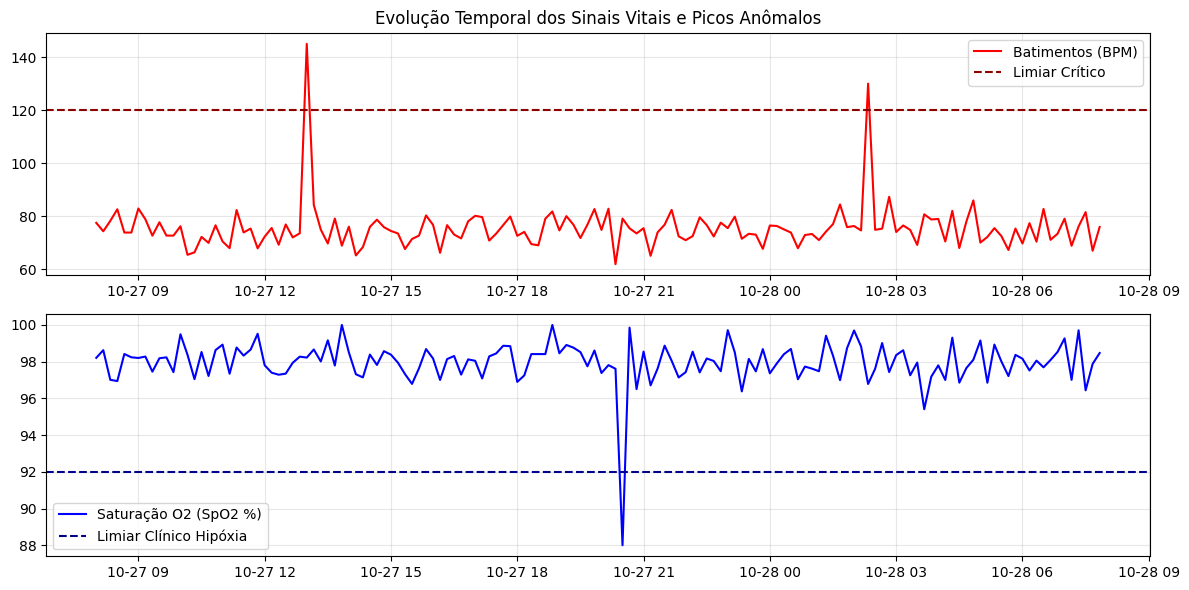

In [21]:
# --- 4. EXIBIÇÃO DA CENTRAL DE ALERTAS INTEGRADOS ---
print("="*75)
print("     CENTRAL DE ALERTAS AUTOMÁTICOS EM TEMPO REAL - EQUIPE MÉDICA")
print("="*75)
todos_alertas = alertas_sinais_vitais + alertas_prescricao + alertas_movimentacao

for i, alerta in enumerate(todos_alertas, 1):
    print(f"ALERTA #{i} | Horário/Dia: {alerta['Momento']} | Gravidade: {alerta['Gravidade']}")
    print(f"  - Métrica Avaliada: {alerta['Métrica']}")
    print(f"  - Evento/Leitura:    {alerta['Valor_Medido']}")
    print("-"*75)

# Exibição visual rápida da Anomalia de Sinais Vitais
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6))
ax1.plot(df_sinais_vitais["Data_Hora"], df_sinais_vitais["Frequencia_Cardiaca"], color='red', label='Batimentos (BPM)')
ax1.axhline(120, color='darkred', linestyle='--', label='Limiar Crítico')
ax1.set_title("Evolução Temporal dos Sinais Vitais e Picos Anômalos")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(df_sinais_vitais["Data_Hora"], df_sinais_vitais["Saturacao_Oxigenio"], color='blue', label='Saturação O2 (SpO2 %)')
ax2.axhline(92, color='darkblue', linestyle='--', label='Limiar Clínico Hipóxia')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()